<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/Pembelajaran_Mesin_2026/blob/main/TG10_JS13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#JOBSHEET 13 - Evaluasi Classifier
##  Artificial Neural Network (ANN)
Artificial Neural Network (ANN) adalah model komputasi yang terinspirasi dari jaringan saraf biologis untuk mengenali pola kompleks dari data melalui proses pelatihan. Sementara itu, evaluasi classifier adalah proses mengukur kinerja dan keakuratan model klasifikasi menggunakan berbagai metrik seperti akurasi, presisi, recall, dan confusion matrix.

##PRAKTIKUM 1

In [2]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.318245
Epoch 1000, Loss: 0.205697
Epoch 2000, Loss: 0.141854
Epoch 3000, Loss: 0.058651
Epoch 4000, Loss: 0.020112
Epoch 5000, Loss: 0.009992
Epoch 6000, Loss: 0.006270
Epoch 7000, Loss: 0.004461
Epoch 8000, Loss: 0.003421
Epoch 9000, Loss: 0.002756
Prediksi: [0.0252 0.9526 0.9512 0.0627]


Ubah jumlah neuron hidden layer menjadi 3.


In [3]:
import numpy as np

np.random.seed(42)          # tambahan: supaya hasil bisa direproduksi

X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

input_size  = 2
hidden_size = 3             # <-- dari 2 menjadi 3
output_size = 1
lr = 0.1

W1 = np.random.randn(input_size, hidden_size)   # (2,3)
b1 = np.zeros((1, hidden_size))                 # (1,3)
W2 = np.random.randn(hidden_size, output_size)  # (3,1)
b2 = np.zeros((1, output_size))                 # (1,1)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(a):      # input = output aktivasi, bukan z
    return a * (1 - a)

for epoch in range(10000):
    # Forward
    a1 = sigmoid(np.dot(X, W1) + b1)
    a2 = sigmoid(np.dot(a1, W2) + b2)

    error = y - a2

    # Backward
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update
    W1 += lr * d_W1; b1 += lr * d_b1
    W2 += lr * d_W2; b2 += lr * d_b2

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}, Loss: {np.mean(np.square(error)):.6f}")

print("Prediksi:", np.round(a2.ravel(), 4))

Epoch 0, Loss: 0.318245
Epoch 1000, Loss: 0.205697
Epoch 2000, Loss: 0.141854
Epoch 3000, Loss: 0.058651
Epoch 4000, Loss: 0.020112
Epoch 5000, Loss: 0.009992
Epoch 6000, Loss: 0.006270
Epoch 7000, Loss: 0.004461
Epoch 8000, Loss: 0.003421
Epoch 9000, Loss: 0.002756
Prediksi: [0.0252 0.9526 0.9512 0.0627]


Tambahan fungsi aktivasi ReLU dan bandingkan hasil.

In [4]:
import numpy as np

X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y = np.array([[0],[1],[1],[0]], dtype=float)

def sigmoid(z):            return 1 / (1 + np.exp(-z))
def sigmoid_derivative(a): return a * (1 - a)
def relu(z):               return np.maximum(0, z)
def relu_derivative(a):    return (a > 0).astype(float)

ACT = {"sigmoid": (sigmoid, sigmoid_derivative),
       "relu":    (relu,    relu_derivative)}

def train(hidden_size=2, activation="sigmoid", lr=0.1, epochs=10000, seed=42):
    rng = np.random.default_rng(seed)
    f, df = ACT[activation]

    W1 = rng.normal(0, 1, (2, hidden_size))   # init identik utk semua konfigurasi
    b1 = np.zeros((1, hidden_size))
    W2 = rng.normal(0, 1, (hidden_size, 1))
    b2 = np.zeros((1, 1))

    hist = []
    for _ in range(epochs):
        a1 = f(X @ W1 + b1)
        a2 = sigmoid(a1 @ W2 + b2)            # output selalu sigmoid
        err = y - a2
        hist.append(float(np.mean(err**2)))

        d2  = err * sigmoid_derivative(a2)
        gW2 = a1.T @ d2;  gb2 = d2.sum(axis=0, keepdims=True)
        d1  = (d2 @ W2.T) * df(a1)
        gW1 = X.T @ d1;   gb1 = d1.sum(axis=0, keepdims=True)

        W1 += lr*gW1; b1 += lr*gb1
        W2 += lr*gW2; b2 += lr*gb2

    a2 = sigmoid(f(X @ W1 + b1) @ W2 + b2)
    hist = np.array(hist)
    hit = np.where(hist < 0.01)[0]
    return {"loss": float(np.mean((y - a2)**2)),
            "acc": float(np.mean((a2 >= 0.5) == y)),
            "pred": np.round(a2.ravel(), 3),
            "ep_conv": int(hit[0]) if hit.size else None,
            "hist": hist}

configs = [(2, "sigmoid"), (3, "sigmoid"), (2, "relu"), (3, "relu")]

print("=== Seed tunggal (42) ===")
print(f"{'Hidden':<7}{'Akt':<9}{'Loss akhir':>12}{'Akurasi':>9}{'Epoch loss<0.01':>17}  Prediksi")
for h, act in configs:
    r = train(h, act, seed=42)
    ep = r['ep_conv'] if r['ep_conv'] is not None else "tidak tercapai"
    print(f"{h:<7}{act:<9}{r['loss']:>12.6f}{r['acc']*100:>8.0f}%{str(ep):>17}  {r['pred']}")

print("\n=== Rata-rata 10 seed (uji kestabilan) ===")
for h, act in configs:
    res = [train(h, act, seed=s) for s in range(10)]
    L = np.array([r['loss'] for r in res])
    sukses = (L < 0.01).mean() * 100
    print(f"hidden={h} {act:<7} | mean={L.mean():.4f} | best={L.min():.6f} "
          f"| worst={L.max():.4f} | sukses={sukses:.0f}%")

=== Seed tunggal (42) ===
Hidden Akt        Loss akhir  Akurasi  Epoch loss<0.01  Prediksi
2      sigmoid      0.005011     100%             7234  [0.069 0.923 0.925 0.062]
3      sigmoid      0.002967     100%             5659  [0.041 0.929 0.962 0.062]
2      relu         0.166694      75%   tidak tercapai  [0.667 0.667 0.667 0.01 ]
3      relu         0.000248     100%              791  [0.02 0.99 0.99 0.02]

=== Rata-rata 10 seed (uji kestabilan) ===
hidden=2 sigmoid | mean=0.0343 | best=0.001978 | worst=0.1764 | sukses=70%
hidden=3 sigmoid | mean=0.0026 | best=0.002028 | worst=0.0034 | sukses=100%
hidden=2 relu    | mean=0.1584 | best=0.000243 | worst=0.2500 | sukses=10%
hidden=3 relu    | mean=0.1334 | best=0.000234 | worst=0.2500 | sukses=30%


Skrip pembanding 4 konfigurasi

In [5]:
import numpy as np

X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y = np.array([[0],[1],[1],[0]], dtype=float)

def sigmoid(z):            return 1 / (1 + np.exp(-z))
def sigmoid_derivative(a): return a * (1 - a)
def relu(z):               return np.maximum(0, z)
def relu_derivative(a):    return (a > 0).astype(float)

ACT = {"sigmoid": (sigmoid, sigmoid_derivative),
       "relu":    (relu,    relu_derivative)}

def train(hidden_size=2, activation="sigmoid", lr=0.1, epochs=10000, seed=42):
    rng = np.random.default_rng(seed)
    f, df = ACT[activation]

    W1 = rng.normal(0, 1, (2, hidden_size))   # init identik utk semua konfigurasi
    b1 = np.zeros((1, hidden_size))
    W2 = rng.normal(0, 1, (hidden_size, 1))
    b2 = np.zeros((1, 1))

    hist = []
    for _ in range(epochs):
        a1 = f(X @ W1 + b1)
        a2 = sigmoid(a1 @ W2 + b2)            # output selalu sigmoid
        err = y - a2
        hist.append(float(np.mean(err**2)))

        d2  = err * sigmoid_derivative(a2)
        gW2 = a1.T @ d2;  gb2 = d2.sum(axis=0, keepdims=True)
        d1  = (d2 @ W2.T) * df(a1)
        gW1 = X.T @ d1;   gb1 = d1.sum(axis=0, keepdims=True)

        W1 += lr*gW1; b1 += lr*gb1
        W2 += lr*gW2; b2 += lr*gb2

    a2 = sigmoid(f(X @ W1 + b1) @ W2 + b2)
    hist = np.array(hist)
    hit = np.where(hist < 0.01)[0]
    return {"loss": float(np.mean((y - a2)**2)),
            "acc": float(np.mean((a2 >= 0.5) == y)),
            "pred": np.round(a2.ravel(), 3),
            "ep_conv": int(hit[0]) if hit.size else None,
            "hist": hist}

configs = [(2, "sigmoid"), (3, "sigmoid"), (2, "relu"), (3, "relu")]

print("=== Seed tunggal (42) ===")
print(f"{'Hidden':<7}{'Akt':<9}{'Loss akhir':>12}{'Akurasi':>9}{'Epoch loss<0.01':>17}  Prediksi")
for h, act in configs:
    r = train(h, act, seed=42)
    ep = r['ep_conv'] if r['ep_conv'] is not None else "tidak tercapai"
    print(f"{h:<7}{act:<9}{r['loss']:>12.6f}{r['acc']*100:>8.0f}%{str(ep):>17}  {r['pred']}")

print("\n=== Rata-rata 10 seed (uji kestabilan) ===")
for h, act in configs:
    res = [train(h, act, seed=s) for s in range(10)]
    L = np.array([r['loss'] for r in res])
    sukses = (L < 0.01).mean() * 100
    print(f"hidden={h} {act:<7} | mean={L.mean():.4f} | best={L.min():.6f} "
          f"| worst={L.max():.4f} | sukses={sukses:.0f}%")

=== Seed tunggal (42) ===
Hidden Akt        Loss akhir  Akurasi  Epoch loss<0.01  Prediksi
2      sigmoid      0.005011     100%             7234  [0.069 0.923 0.925 0.062]
3      sigmoid      0.002967     100%             5659  [0.041 0.929 0.962 0.062]
2      relu         0.166694      75%   tidak tercapai  [0.667 0.667 0.667 0.01 ]
3      relu         0.000248     100%              791  [0.02 0.99 0.99 0.02]

=== Rata-rata 10 seed (uji kestabilan) ===
hidden=2 sigmoid | mean=0.0343 | best=0.001978 | worst=0.1764 | sukses=70%
hidden=3 sigmoid | mean=0.0026 | best=0.002028 | worst=0.0034 | sukses=100%
hidden=2 relu    | mean=0.1584 | best=0.000243 | worst=0.2500 | sukses=10%
hidden=3 relu    | mean=0.1334 | best=0.000234 | worst=0.2500 | sukses=30%


##PRAKTIKUM 2

In [7]:
# ============================================================
# 1. IMPORT LIBRARY
# ============================================================
import numpy as np
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility (agar hasil konsisten setiap dijalankan)
np.random.seed(42)
tf.random.set_seed(42)


# ============================================================
# 2. LOAD DATASET
# ============================================================
iris = load_iris()
X = iris.data                      # fitur: 4 kolom
y = iris.target.reshape(-1, 1)     # label: 0, 1, 2

# One-hot encoding label
# Catatan: gunakan sparse_output=False (bukan sparse=False)
# untuk scikit-learn versi >= 1.2
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data: 80% latih, 20% uji
# stratify=iris.target menjaga proporsi tiap kelas seimbang
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=iris.target
)

# Normalisasi fitur (opsional tapi disarankan untuk jaringan saraf)
# fit HANYA pada data latih, lalu transform pada data uji
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print("Bentuk X_train:", X_train.shape)
print("Bentuk X_test :", X_test.shape)
print("Nama kelas    :", iris.target_names)


# ============================================================
# 3. BANGUN MODEL
# ============================================================
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),            # layer input eksplisit
    tf.keras.layers.Dense(10, activation='relu'), # hidden layer 1
    tf.keras.layers.Dense(8,  activation='relu'), # hidden layer 2
    tf.keras.layers.Dense(3,  activation='softmax') # output: 3 kelas
])

model.summary()   # tampilkan arsitektur & jumlah parameter


# ============================================================
# 4. KOMPILASI DAN LATIH MODEL
# ============================================================
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',   # sesuai label one-hot + softmax
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=8,
    validation_split=0.2,   # sisihkan 20% data latih untuk validasi
    verbose=1
)


# ============================================================
# 5. EVALUASI HASIL
# ============================================================
# Evaluasi kuantitatif pada data uji
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nLoss uji   : {loss:.4f}")
print(f"Akurasi uji: {acc:.4f}  ({acc*100:.2f}%)")

# Prediksi kelas
y_pred_prob  = model.predict(X_test, verbose=0)
y_pred_label = np.argmax(y_pred_prob, axis=1)
y_true_label = np.argmax(y_test, axis=1)

# Laporan klasifikasi lengkap (precision, recall, f1-score)
print("\nClassification Report:")
print(classification_report(
    y_true_label, y_pred_label, target_names=iris.target_names
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_true_label, y_pred_label))

Bentuk X_train: (120, 4)
Bentuk X_test : (30, 4)
Nama kelas    : ['setosa' 'versicolor' 'virginica']


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.2188 - loss: 1.1843 - val_accuracy: 0.3333 - val_loss: 1.1153
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.2188 - loss: 1.1395 - val_accuracy: 0.3750 - val_loss: 1.0825
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.3125 - loss: 1.1069 - val_accuracy: 0.5000 - val_loss: 1.0580
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4062 - loss: 1.0819 - val_accuracy: 0.6250 - val_loss: 1.0367
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4688 - loss: 1.0596 - val_accuracy: 0.6667 - val_loss: 1.0153
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5833 - loss: 1.0328 - val_accuracy: 0.6667 - val_loss: 0.9880
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6250 - loss: 1.0021 - val_accuracy: 0.6250 - val_loss: 0.9589
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6562 - loss: 0.9706 - val_accuracy: 0.6250 - v

##PRAKTIKUM 3

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - loss: 0.5337
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - loss: 0.5227
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.5117
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.5009
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 0.4902
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - loss: 0.4796
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - loss: 0.4691
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - loss: 0.4588
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - loss: 0.4486
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - loss: 0.4385
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 0.4286
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - loss: 0.4188
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 0.4092
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - loss: 0.3996
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - loss: 0.3902
Epoch 16/10

ubah learning rate


In [4]:
# ============================================================
# CELL 1 — SOAL 1: UBAH LEARNING RATE
# ============================================================
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ---------- Dataset dummy ----------
data = pd.DataFrame({
    'luas' : [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})
X_raw = data[['luas']].to_numpy(dtype='float32')
y_raw = data[['harga']].to_numpy(dtype='float32')

# ---------- Split DULU dengan random_state TETAP ----------
# Penting: semua learning rate harus memakai data latih/uji yang SAMA
Xtr_raw, Xte_raw, ytr_raw, yte_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42)

# ---------- Normalisasi: fit HANYA di data latih ----------
sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(Xtr_raw);  X_test = sx.transform(Xte_raw)
y_train = sy.fit_transform(ytr_raw);  y_test = sy.transform(yte_raw)
X_all   = sx.transform(X_raw);        y_all  = sy.transform(y_raw)

print("Data latih (luas):", Xtr_raw.ravel(), "→ harga:", ytr_raw.ravel())
print("Data uji   (luas):", Xte_raw.ravel(), "→ harga:", yte_raw.ravel())

# ---------- Konfigurasi eksperimen ----------
LR_LIST = [0.0001, 0.001, 0.01, 0.1, 0.5]   # 0.001 = default Adam (baseline)
EPOCHS  = 100      # sama seperti kode asli (naikkan ke 500 untuk melihat LR kecil menyusul)
BATCH   = 4        # full-batch (4 sampel latih) = setara default kode asli
SEED    = 42

def build_model():
    return keras.Sequential([
        keras.layers.Input(shape=(1,)),          # pengganti input_shape di Dense
        keras.layers.Dense(10, activation='relu'),
        keras.layers.Dense(1)                    # output linear untuk regresi
    ])

results = []
print(f"\n{'LR':>8} | {'Loss train':>11} | {'Loss uji':>9} | {'Loss semua':>11} | {'Detik':>6}")
print("-" * 62)

for lr in LR_LIST:
    keras.backend.clear_session()          # bersihkan graph antar eksperimen
    keras.utils.set_random_seed(SEED)      # bobot awal IDENTIK untuk semua LR

    model = build_model()
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse')

    t0 = time.time()
    hist = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH, verbose=0)
    dt = time.time() - t0

    loss_train = float(model.evaluate(X_train, y_train, verbose=0))
    loss_test  = float(model.evaluate(X_test,  y_test,  verbose=0))
    loss_all   = float(model.evaluate(X_all,   y_all,   verbose=0))
    pred_all   = sy.inverse_transform(model.predict(X_all, verbose=0)).ravel()

    results.append(dict(lr=lr, loss_train=loss_train, loss_test=loss_test,
                        loss_all=loss_all, waktu=dt,
                        history=hist.history['loss'], pred_harga=pred_all))

    print(f"{lr:>8.4f} | {loss_train:>11.5f} | {loss_test:>9.5f} | {loss_all:>11.5f} | {dt:>6.2f}")


Data latih (luas): [90. 70. 50. 80.] → harga: [900. 700. 500. 800.]
Data uji   (luas): [60.] → harga: [600.]

      LR |  Loss train |  Loss uji |  Loss semua |  Detik
--------------------------------------------------------------
  0.0001 |     1.12369 |   1.30254 |     1.15946 |  23.41
  0.0010 |     0.70712 |   0.74116 |     0.71393 |   9.78
  0.0100 |     0.00265 |   0.01105 |     0.00433 |   6.40
  0.1000 |     0.00001 |   0.00933 |     0.00187 |   5.19
  0.5000 |     0.00007 |   0.00012 |     0.00008 |   6.20


membandingkan learning rate

=== TABEL PERBANDINGAN LOSS (MSE pada data ternormalisasi) ===


,Learning Rate,Loss train,Loss uji,Loss semua,RMSE (rupiah),Δ vs default,Kualitas
0,0.0001,1.12369,1.30254,1.15946,159.26,0.41657,hampir tidak belajar
1,0.0010,0.70712,0.74116,0.71393,124.97,0.00000,cukup
2,0.0100,0.00265,0.01105,0.00433,9.73,-0.70447,sangat baik
3,0.1000,0.00001,0.00933,0.00187,6.40,-0.70711,sangat baik
4,0.5000,0.00007,0.00012,0.00008,1.35,-0.70705,sangat baik



Baseline (lr=0.001) : loss train = 0.70712
LR terbaik          : 0.1  → loss train = 0.00001
LR terburuk         : 0.0001 → loss train = 1.12369
Perbaikan           : 114342.9× lebih kecil dari default

Acuan: y dinormalisasi (variansi = 1), jadi loss ≈ 1.0 berarti model
hanya menebak nilai rata-rata. Loss < 1 = model mulai belajar pola.


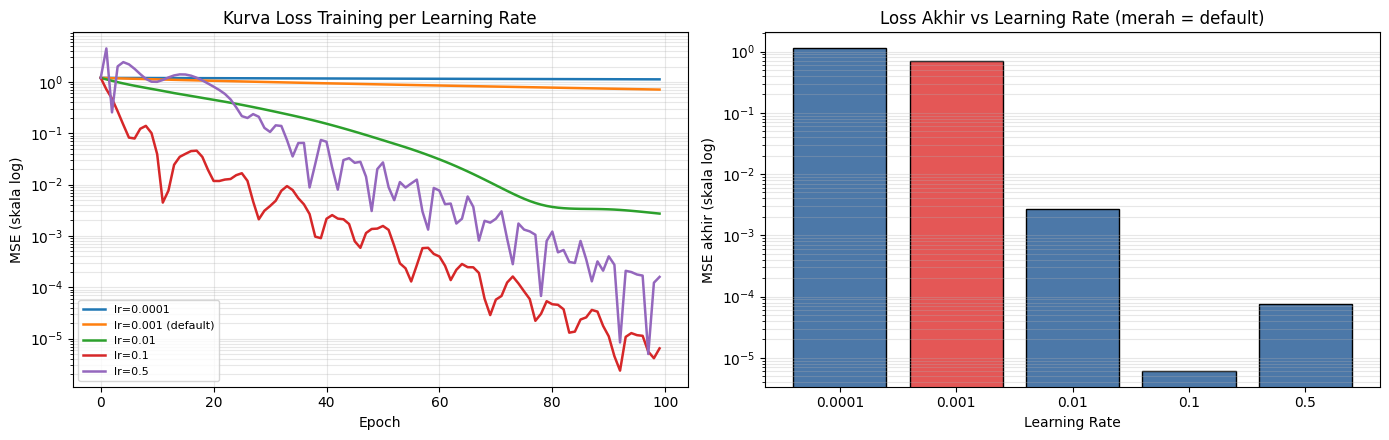


=== PREDIKSI HARGA (satuan asli) ===


,luas,harga_aktual,pred lr=0.0001,pred lr=0.001,pred lr=0.01,pred lr=0.1,pred lr=0.5
0,50,500,806.000000,748.500000,499.399994,499.399994,502.299988
1,60,600,768.799988,727.299988,584.500000,585.700012,601.599976
2,70,700,731.500000,709.500000,697.599976,700.299988,701.000000
3,80,800,777.400024,800.599976,813.099976,800.000000,800.299988
4,90,900,843.900024,894.000000,892.599976,899.799988,899.599976


In [5]:
# ============================================================
# CELL 2 — SOAL 2: BANDINGKAN HASIL LOSS
# ============================================================
import matplotlib.pyplot as plt

baseline = next(r for r in results if r['lr'] == 0.001)   # Adam default

def kualitas(loss):
    if not np.isfinite(loss):  return 'DIVERGEN (NaN)'
    if loss < 0.01:            return 'sangat baik'
    if loss < 0.10:            return 'baik'
    if loss < 0.90:            return 'cukup'
    return 'hampir tidak belajar'

rows = []
for r in results:
    rmse_rupiah = np.sqrt(r['loss_all']) * sy.scale_[0]   # kembalikan ke satuan harga
    rows.append({
        'Learning Rate' : r['lr'],
        'Loss train'    : round(r['loss_train'], 5),
        'Loss uji'      : round(r['loss_test'], 5),
        'Loss semua'    : round(r['loss_all'], 5),
        'RMSE (rupiah)' : round(rmse_rupiah, 2),
        'Δ vs default'  : round(r['loss_train'] - baseline['loss_train'], 5),
        'Kualitas'      : kualitas(r['loss_train']),
    })

df = pd.DataFrame(rows)
print("=== TABEL PERBANDINGAN LOSS (MSE pada data ternormalisasi) ===")
display(df)

best  = min(results, key=lambda r: r['loss_train'])
worst = max(results, key=lambda r: r['loss_train'])
print(f"\nBaseline (lr=0.001) : loss train = {baseline['loss_train']:.5f}")
print(f"LR terbaik          : {best['lr']}  → loss train = {best['loss_train']:.5f}")
print(f"LR terburuk         : {worst['lr']} → loss train = {worst['loss_train']:.5f}")
if best['loss_train'] > 0:
    print(f"Perbaikan           : {baseline['loss_train'] / best['loss_train']:.1f}× lebih kecil dari default")
print("\nAcuan: y dinormalisasi (variansi = 1), jadi loss ≈ 1.0 berarti model")
print("hanya menebak nilai rata-rata. Loss < 1 = model mulai belajar pola.")

# ---------- Grafik 1: kurva loss | Grafik 2: bar loss akhir ----------
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

for r in results:
    label = f"lr={r['lr']}" + (" (default)" if r['lr'] == 0.001 else "")
    ax[0].plot(r['history'], label=label, linewidth=1.8)
ax[0].set_yscale('log')
ax[0].set_title('Kurva Loss Training per Learning Rate')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('MSE (skala log)')
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3, which='both')

labels = [str(r['lr']) for r in results]
vals   = [r['loss_train'] for r in results]
colors = ['#E45756' if r['lr'] == 0.001 else '#4C78A8' for r in results]
ax[1].bar(labels, vals, color=colors, edgecolor='black')
ax[1].set_yscale('log')
ax[1].set_title('Loss Akhir vs Learning Rate (merah = default)')
ax[1].set_xlabel('Learning Rate'); ax[1].set_ylabel('MSE akhir (skala log)')
ax[1].grid(alpha=.3, axis='y', which='both')

plt.tight_layout(); plt.show()

# ---------- Prediksi harga: bukti kualitas model ----------
pred_df = pd.DataFrame({'luas': data['luas'].values,
                        'harga_aktual': data['harga'].values})
for r in results:
    pred_df[f"pred lr={r['lr']}"] = np.round(r['pred_harga'], 1)
print("\n=== PREDIKSI HARGA (satuan asli) ===")
display(pred_df)

Shape X: (20640, 8) | Shape y: (20640,)
Fitur  : ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target : median nilai rumah (satuan $100.000)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

Berhenti di epoch 127


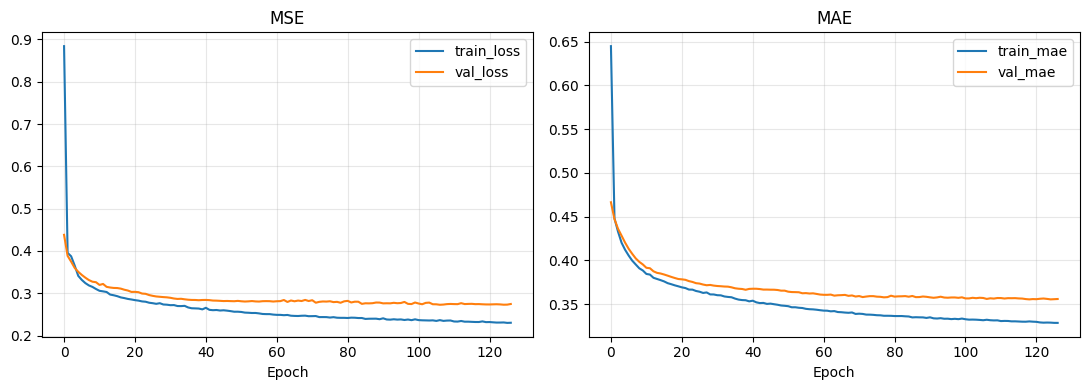

RMSE : 0.5223  (≈ $52,228)
MAE  : 0.3560
R²   : 0.7918


In [7]:
# MLP Regresi (Keras) — versi diperbaiki
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

# 1. Load (pengganti load_boston)
data = fetch_california_housing()
X, y = data.data, data.target
print("Shape X:", X.shape, "| Shape y:", y.shape)
print("Fitur  :", list(data.feature_names))
print("Target : median nilai rumah (satuan $100.000)")

# 2. Preprocess — split DULU, scaler fit HANYA di data latih
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)

# 3. Build model
model = Sequential([
    Input(shape=(X_train.shape[1],)),      # pengganti input_shape di Dense
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)                               # regresi: output linear
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])
model.summary()

# 4. Train
es = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
h = model.fit(X_train, y_train,
              validation_data=(X_val, y_val),
              epochs=200, batch_size=32,
              callbacks=[es], verbose=0)
print(f"Berhenti di epoch {len(h.history['loss'])}")

# 5. Plot (nama key MAE bisa beda antar versi Keras → dideteksi otomatis)
mae_key     = 'mae' if 'mae' in h.history else 'mean_absolute_error'
val_mae_key = 'val_' + mae_key

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend(); plt.title('MSE'); plt.xlabel('Epoch'); plt.grid(alpha=.3)

plt.subplot(1, 2, 2)
plt.plot(h.history[mae_key], label='train_mae')
plt.plot(h.history[val_mae_key], label='val_mae')
plt.legend(); plt.title('MAE'); plt.xlabel('Epoch'); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

# 6. Evaluasi
pred = model.predict(X_val, verbose=0)
rmse = np.sqrt(mean_squared_error(y_val, pred))
print(f"RMSE : {rmse:.4f}  (≈ ${rmse*100_000:,.0f})")
print(f"MAE  : {mean_absolute_error(y_val, pred):.4f}")
print(f"R²   : {r2_score(y_val, pred):.4f}")